In [34]:
import numpy as np
import pandas as pd

In [35]:
df = pd.read_csv('016-social-network-ads.csv')

In [36]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [37]:
df = df.iloc[ : , 2 : ]
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [38]:
import seaborn as sns

<Axes: xlabel='Age', ylabel='EstimatedSalary'>

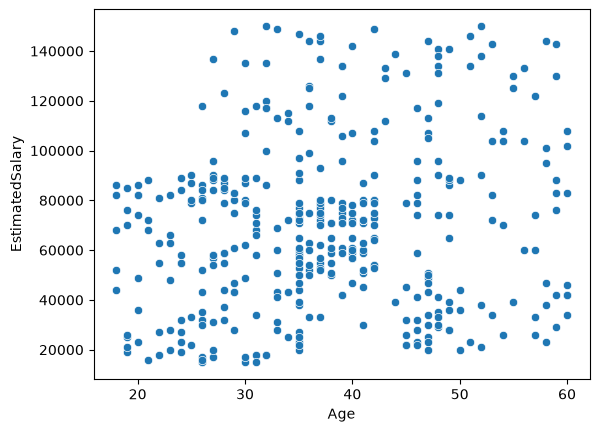

In [39]:
sns.scatterplot(
    x = df.iloc[ : , 0],
    y = df.iloc[ : , 1]
)

In [40]:
X = df.iloc[ : , 0:2]
y = df.iloc[ : , -1]

In [41]:
X

,Age,EstimatedSalary
0,19,19000
1,35,20000
2,26,43000
3,27,57000
4,19,76000
...,...,...
395,46,41000
396,51,23000
397,50,20000
398,36,33000


In [42]:
y

0      0
1      0
2      0
3      0
4      0
      ..
395    1
396    1
397    1
398    0
399    1
Name: Purchased, Length: 400, dtype: int64

In [43]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 2)

In [44]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [45]:
model = Sequential()

model.add(Dense(128, input_dim = 2, activation = 'relu'))
model.add(Dense(1, activation = 'sigmoid'))

d:\Rat_Race\AI-ML\env\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [46]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

In [47]:
model.compile(
    optimizer = 'adam',
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)

In [48]:
history = model.fit(
    X_train,
    y_train,
    validation_data = (X_test, y_test),
    epochs = 100,
    verbose = 1
)

Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4781 - loss: 815.5150 - val_accuracy: 0.4000 - val_loss: 177.8138
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5844 - loss: 177.2603 - val_accuracy: 0.4000 - val_loss: 216.9029
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5594 - loss: 159.8109 - val_accuracy: 0.4000 - val_loss: 164.4741
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5219 - loss: 163.8137 - val_accuracy: 0.6000 - val_loss: 9.3606
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4781 - loss: 162.5454 - val_accuracy: 0.6000 - val_loss: 250.1577
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5031 - loss: 154.9475 - val_accuracy: 0.6000 - val_loss: 176.9781
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5219 - loss: 112.2049 - val_accuracy: 0.6000 - val_loss: 156.8263
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5344 - loss: 66.100

In [49]:
import matplotlib.pyplot as plt

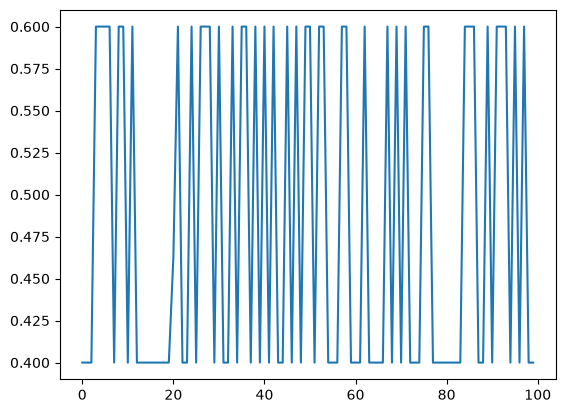

In [50]:
plt.plot(history.history['val_accuracy'])

### **Applying scaling**

In [51]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [52]:
# X_train_scaled

In [53]:
# y_test_scaled

<Axes: >

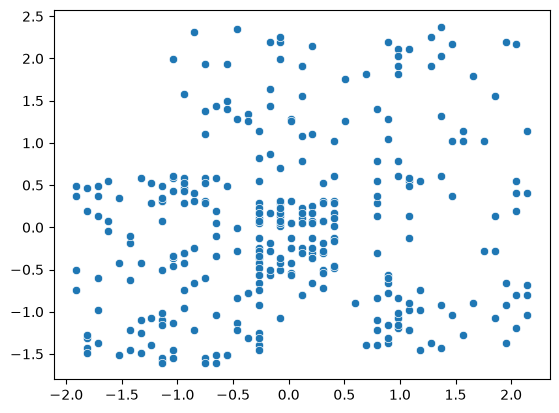

In [55]:
sns.scatterplot(
    x = X_train_scaled[ : , 0],
    y = X_train_scaled[ : , 1]
)

In [56]:
model = Sequential()

model.add(Dense(128, input_dim = 2, activation = 'relu'))
model.add(Dense(1, activation = 'sigmoid'))

model.compile(
    optimizer = 'adam',
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_data = (X_test_scaled, y_test),
    epochs = 100
)

Epoch 1/100


d:\Rat_Race\AI-ML\env\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4437 - loss: 0.6979 - val_accuracy: 0.6625 - val_loss: 0.6478
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7469 - loss: 0.6332 - val_accuracy: 0.8375 - val_loss: 0.5863
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8375 - loss: 0.5800 - val_accuracy: 0.8625 - val_loss: 0.5362
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8469 - loss: 0.5361 - val_accuracy: 0.8500 - val_loss: 0.4951
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8656 - loss: 0.4995 - val_accuracy: 0.8250 - val_loss: 0.4614
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8625 - loss: 0.4685 - val_accuracy: 0.8250 - val_loss: 0.4334
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8594 - loss: 0.4420 - val_accuracy: 0.8250 - val_loss: 0.4099
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8594 - loss: 0.4189 - val_accuracy: 0.8250 - val_loss: 0.

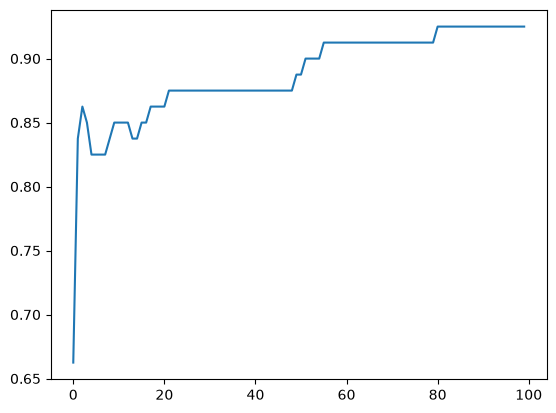

In [58]:
plt.plot(history.history['val_accuracy'])